# Transfer learning MobileNetV3-Small (BISINDO A-Z)

Notebook tipis: semua logika ada di `src/train_transfer.py`. Notebook ini hanya mengatur eksperimen dan menampilkan hasil.

- **Data dan split:** dari `configs/config.yaml` (`data_dir`, `split_path` = split beku). Notebook ini tidak membuat atau mengubah split.
- **Hyperparameter dasar:** `configs/transfer.yaml`; ubah yang perlu di sel konfigurasi.
- **Satu run = satu perubahan** dari run pembanding. Hasil di `results/transfer/<run_name>/`.
- **Tuning pakai val.** Set `EVALUATE_TEST = False` selama tuning; nyalakan sekali untuk hasil akhir.
- **Mode Cepat (RAM Cache + Multi-Thread):** Gambar otomatis di-preload ke RAM (`256x256`) pada awal run pertama sehingga epoch berikutnya tidak perlu membaca ulang file dari disk/OneDrive.

In [1]:
import sys, json, importlib
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "configs").exists():      # dijalankan dari notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import pandas as pd
from IPython.display import Image as IPImage, display
import train_transfer as tt
importlib.reload(tt)                     # pastikan perubahan kode terbaru di train_transfer.py termuat
print("root repo:", ROOT)

root repo: C:\Users\Pongo\OneDrive\Dokumen\TUGAS SEM 5\Computer Vision\PROJECT\Bisindo-cv


## 1. Konfigurasi eksperimen

In [2]:
# None = pakai nilai dari configs/transfer.yaml
OVERRIDES = dict(
    run_name="mnv3s_full",     # nama unik per eksperimen (run yang sudah ada tidak ditimpa)
    mode="full",               # head = baseline | partial = metode utama | full
    unfreeze_blocks=None,      # hanya mode partial, mis. 2 atau 3
    epochs=12,
    batch_size=64,
    draft_size=256,
    patience=4,
    cache_ram=True,
    pretrained=None,
    # lr_head=None, lr_backbone=None, augment=None, class_weights=None, seed=None, overwrite=None
)
EVALUATE_TEST = True           # False selama tuning

cfg = tt.build_cfg(OVERRIDES)
show = {k: v for k, v in cfg.items() if k not in ("data_dir", "split_path", "label_map_path", "results_dir")}
print(json.dumps(show, indent=2))
print("split:", tt._rel(cfg["split_path"]))

{
  "run_name": "mnv3s_full",
  "mode": "full",
  "unfreeze_blocks": 2,
  "pretrained": true,
  "batch_size": 64,
  "epochs": 12,
  "lr_head": 0.001,
  "lr_backbone": 0.0001,
  "weight_decay": 0.0001,
  "class_weights": false,
  "augment": true,
  "patience": 4,
  "num_workers": 0,
  "draft_size": 256,
  "cache_ram": true,
  "device": "auto",
  "overwrite": false,
  "seed": 42,
  "img_size": 224
}
split: splits/split_v2.csv


## 2. Cek data dan split

In [3]:
loaders, df = tt.make_loaders(cfg)          # juga memeriksa file contoh & preload ke RAM
print(df["split"].value_counts().to_dict())
display(pd.crosstab(df["label"], df["split"])[["train", "val", "test"]].T)
x, y = next(iter(loaders["train"]))
print("satu batch:", tuple(x.shape), "| label", int(y.min()), "-", int(y.max()))

Preload 4462 gambar ke RAM (256px, 16 threads) selesai dalam 38.0s
{'train': 3114, 'val': 675, 'test': 673}


label,A,B,C,D,E,F,G,H,I,J,...,Q,R,S,T,U,V,W,X,Y,Z
split,,,,,,,,,,,,,,,,,,,,,
train,115,117,117,117,117,121,121,121,121,117,...,121,119,121,121,121,120,118,122,122,122
val,25,26,26,26,26,26,26,26,26,26,...,26,26,26,26,26,26,26,26,26,26
test,25,25,26,26,25,26,26,26,26,26,...,26,26,26,26,26,26,26,26,26,26


satu batch: (64, 3, 224, 224) | label 0 - 25


## 3. Latih

In [4]:
result = tt.run(cfg, evaluate_test=EVALUATE_TEST)

Run: mnv3s_full | mode=full | device=cpu | torch 2.14.1+cpu
Split: splits/split_v2.csv (md5 f71002d1) | {'train': 3114, 'val': 675, 'test': 673}
Parameter: total 1,544,506 | dilatih 1,544,506 (100.00%)
Epoch 01/12 | train loss 2.8193 acc 0.232 | val loss 2.1454 acc 0.370 f1 0.346 | 147.7s
Epoch 02/12 | train loss 1.5583 acc 0.582 | val loss 1.4447 acc 0.516 f1 0.510 | 151.3s
Epoch 03/12 | train loss 0.9233 acc 0.724 | val loss 1.0401 acc 0.659 f1 0.652 | 114.5s
Epoch 04/12 | train loss 0.6492 acc 0.801 | val loss 0.8865 acc 0.699 f1 0.693 | 114.1s
Epoch 05/12 | train loss 0.4887 acc 0.842 | val loss 0.7621 acc 0.745 f1 0.746 | 145.9s
Epoch 06/12 | train loss 0.3714 acc 0.883 | val loss 0.7117 acc 0.751 f1 0.752 | 145.5s
Epoch 07/12 | train loss 0.3014 acc 0.905 | val loss 0.6499 acc 0.776 f1 0.775 | 143.8s
Epoch 08/12 | train loss 0.2363 acc 0.932 | val loss 0.6191 acc 0.767 f1 0.770 | 143.8s
Epoch 09/12 | train loss 0.2142 acc 0.929 | val loss 0.6222 acc 0.794 f1 0.789 | 145.3s
Epoch 

## 4. Hasil run ini

model terbaik: epoch 11 | val macro-F1 0.806
[test] {'accuracy': 0.8113, 'macro_f1': 0.8082, 'weighted_f1': 0.8078}
latency (ms): {'total_ms_median': 58.2, 'forward_ms_median': 27.9}
CATATAN: Split tanpa grup perangkat/latar: gambar dengan kondisi sama bisa ada di train dan test, jadi skor bisa lebih optimis daripada kondisi nyata.


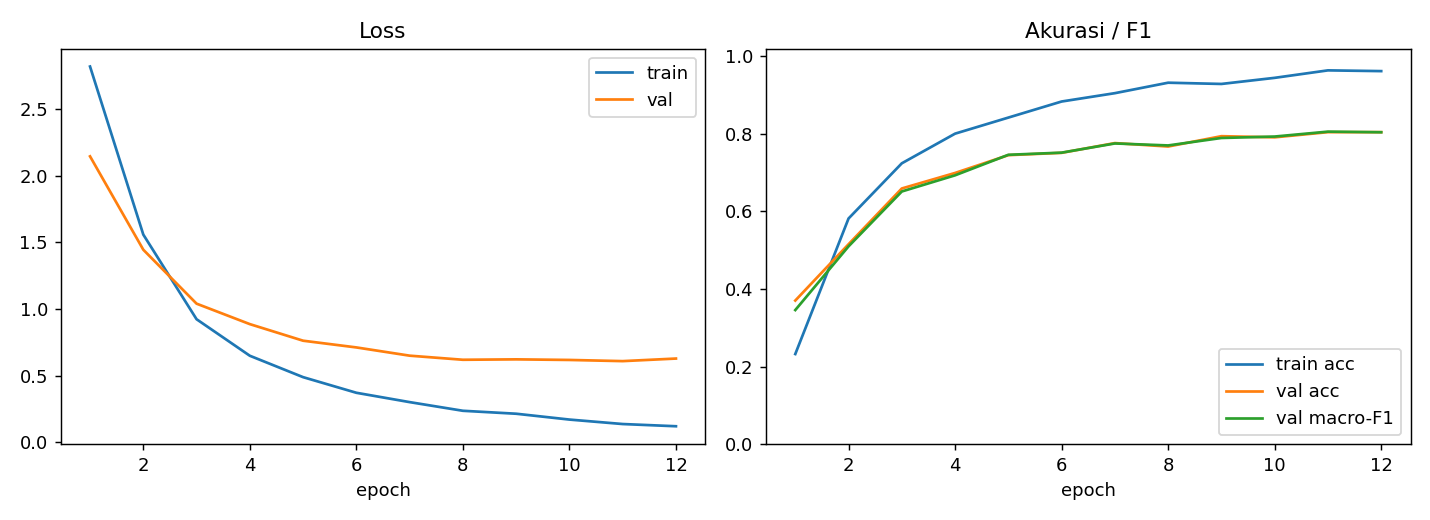

In [5]:
out, m = result["out_dir"], result["metrics"]
split = m["report_split"]
print(f"model terbaik: epoch {m['best_epoch']} | val macro-F1 {m['best_val_macro_f1']:.3f}")
print(f"[{split}]", {k: round(v, 4) for k, v in (m["test"] or m["val"]).items()})
print("latency (ms):", {k: round(v, 1) for k, v in m["latency_ms"].items() if k != "n"})
if "catatan" in m:
    print("CATATAN:", m["catatan"])
display(IPImage(str(out / "curves.png")))

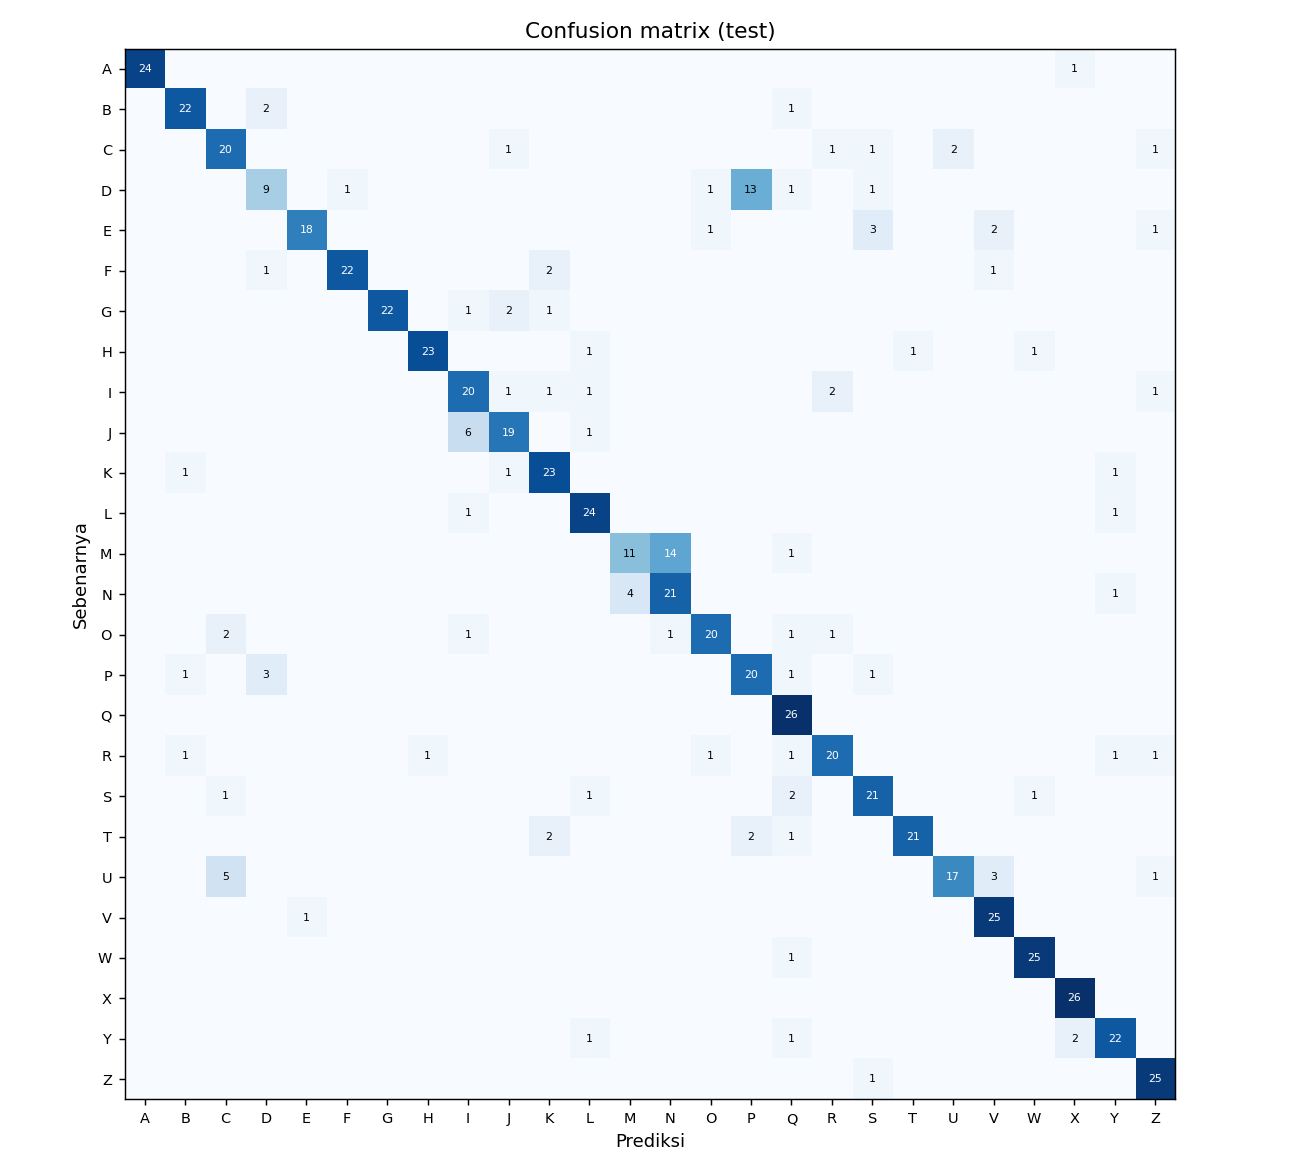

Kelas paling lemah:


,kelas,precision,recall,f1,support
3,D,0.600000,0.346154,0.439024,26
12,M,0.733333,0.423077,0.536585,26
15,P,0.571429,0.769231,0.655738,26
13,N,0.583333,0.807692,0.677419,26
8,I,0.689655,0.769231,0.727273,26
2,C,0.714286,0.769231,0.740741,26
20,U,0.894737,0.653846,0.755556,26
9,J,0.791667,0.730769,0.760000,26


Pasangan huruf yang paling sering tertukar:


,sebenarnya,diprediksi,jumlah
0,M,N,14
1,D,P,13
2,J,I,6
3,U,C,5
4,N,M,4
5,E,S,3
6,P,D,3
7,U,V,3
8,B,D,2
9,C,U,2


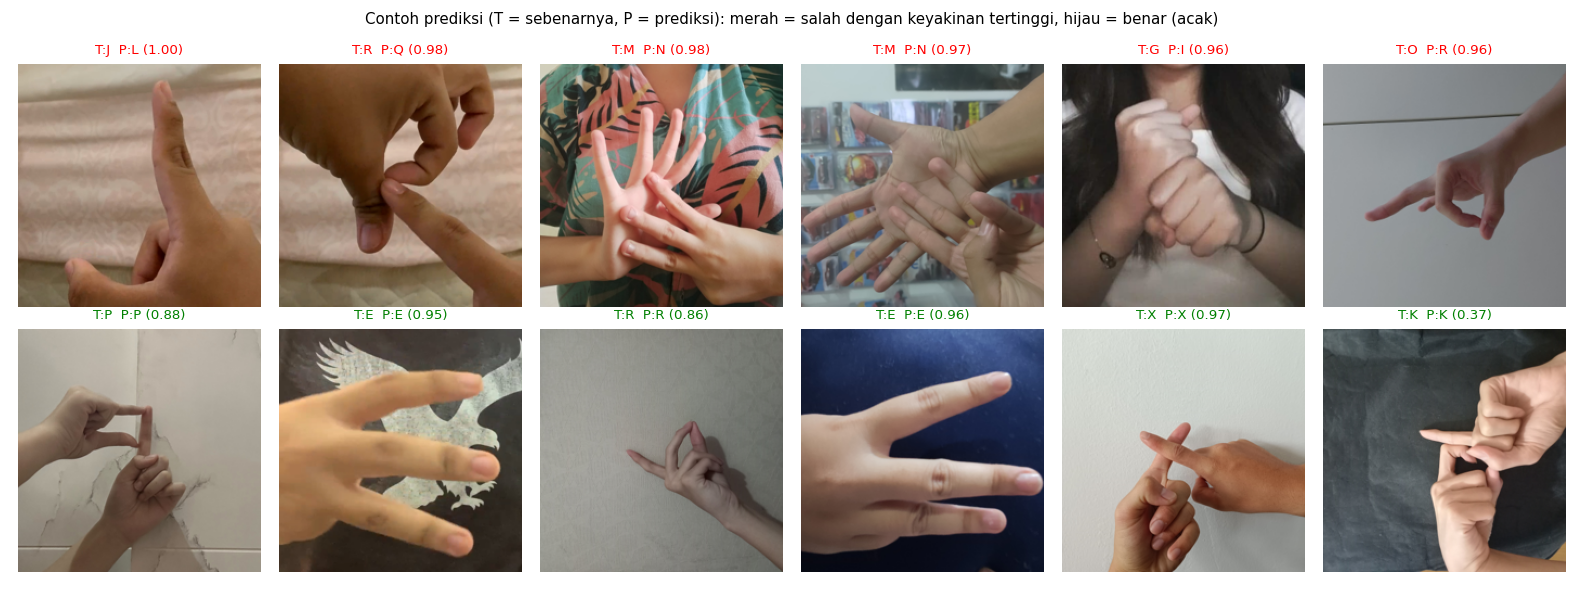

In [6]:
display(IPImage(str(out / f"confusion_matrix_{split}.png")))
pc = pd.read_csv(out / f"per_class_{split}.csv").sort_values("f1")
print("Kelas paling lemah:")
display(pc.head(8))
print("Pasangan huruf yang paling sering tertukar:")
display(pd.read_csv(out / f"top_confusions_{split}.csv").head(10))
display(IPImage(str(out / f"sample_predictions_{split}.png")))

## 5. Perbandingan semua run

In [7]:
cmp = tt.compare_runs()                      # juga menyimpan results/transfer/comparison.csv
cmp

,run,mode,unfreeze,lr_head,lr_backbone,augment,class_w,seed,epochs,best_ep,val_f1,test_acc,test_f1,ms,trainable
0,mnv3s_full,full,None,0.001,0.0001,True,False,42,12,11,0.8058,0.8113,0.8082,58.2,1544506
1,mnv3s_head2,head,None,0.001,0.0001,True,False,42,20,18,0.4799,0.5275,0.5248,28.6,26650


## Catatan
- **Eksperimen terkontrol:** ubah satu hal per run (mis. `mode` head -> partial, atau `unfreeze_blocks` 2 -> 3, atau `augment`), nama run baru, split dan seed sama. Tabel di atas menunjukkan perbedaannya.
- **Keterbatasan split:** `split_v2` tidak memakai grup perangkat/latar, sehingga kondisi foto yang sama bisa ada di train dan test dan skor bisa lebih optimis daripada kondisi nyata. Jangan membandingkan angka dengan notebook lintas-kondisi (dataset Kaggle).
- **Ketidakseimbangan per kelas** kecil, tetapi laporkan macro-F1 dan akurasi per kelas, bukan hanya accuracy.
- **Demo:** `python src/demo.py --run <run_name> --image foto.jpg` (offline) atau `--webcam` (jalankan di terminal, bukan di notebook).